## Load Libraries

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from glaciation_time_estimator.auxiliary_func.chunking_data import ChunkLoader
from glaciation_time_estimator.auxiliary_func.config_reader import read_config

In [2]:
# glac = pd.read_parquet("/wolke_scratch/dnikolo/GTE_Validation/Pixel_py_pixel_with_cth/CTH_included/Results/Agg_03_glaciations_20070501.0000_20070512.0000.parquet")
# cloud = pd.read_parquet("/wolke_scratch/dnikolo/GTE_Validation/Pixel_py_pixel_with_cth/CTH_included/Results/Agg_03_clouds_20070501.0000_20070512.0000.parquet")

## Load and classify data

In [3]:
from pathlib import Path
import pandas as pd

results_dir = Path("/wolke_scratch/dnikolo/GTE_Validation/Modis_six_months/Results")

cloud_files = sorted(results_dir.glob("Agg_03_clouds_*.parquet"))
glac_files = sorted(results_dir.glob("Agg_03_glaciations_*.parquet"))

cloud_df = pd.concat(
    [pd.read_parquet(f) for f in cloud_files],
    ignore_index=True
)

glac_df = pd.concat(
    [pd.read_parquet(f) for f in glac_files],
    ignore_index=True
)

cloud_out = results_dir / "Agg_03_clouds_concat.parquet"
glac_out = results_dir / "Agg_03_glaciations_concat.parquet"

cloud_df.to_parquet(cloud_out, index=False)
glac_df.to_parquet(glac_out, index=False)

print(f"Saved: {cloud_out}  | rows = {len(cloud_df)}")
print(f"Saved: {glac_out}   | rows = {len(glac_df)}")

KeyboardInterrupt: 

In [4]:
df_clouds = pd.read_parquet("/wolke_scratch/dnikolo/GTE_Validation/Modis_one_month/Results/Agg_03_clouds_20070101.0000_20070115.0000.parquet")
df_glac = pd.read_parquet("/wolke_scratch/dnikolo/GTE_Validation/Modis_one_month/Results/Agg_03_glaciations_20070101.0000_20070115.0000.parquet")

In [5]:
def filter_df(df):
    return df[(~df.is_large_pix_cloud) & (abs(df.avg_lat)>30)]
df_glac = filter_df(df_glac)
df_clouds = filter_df(df_clouds)

In [ ]:
# folder = Path("/wolke_scratch/dnikolo/GTE_Validation/MODIS_pixel_by_pixel_full_year/")
# gte_config = read_config("/wolke_scratch/dnikolo/Glaciation_time_estimator/configs/Validation/n2o_2007_01_01.yaml")

In [7]:
# data_loader = ChunkLoader([2007],gte_config)

In [8]:
# df_clouds = data_loader.cloud_chunk
# df_glac = data_loader.glac_chunk

In [42]:
ALLOWED_CTH_DEV=500

def get_mean_val_ice_frac_hist(row):
    if_hist = row["val_ice_frac_hist"]
    if (np.isnan(if_hist) | (if_hist==-1)).all():
        return np.nan
    return if_hist[~np.isnan(if_hist)].mean()

def get_mean_val_ice_frac_dev(row):
    if check_val_seviri_coincidence(row):
        if_hist_dev = row["val_ice_frac_dev_hist"]
        if (np.isnan(if_hist_dev) | (if_hist_dev==-99)).all():
            return np.nan
        if_hist_dev = if_hist_dev[(~np.isnan(if_hist_dev)) & (if_hist_dev >-99)]
        if if_hist_dev.size>0:
            return if_hist_dev.mean()
        else:
            return np.nan
    else: return np.nan

def get_if_dev_same_cloud(row):
    try:
        if check_val_seviri_coincidence(row):
            if_hist_dev = row["val_ice_frac_dev_hist"]
            if_hist_dev = if_hist_dev[~np.isnan(if_hist_dev)]
            if_hist_dev = if_hist_dev[if_hist_dev >-99]
            if if_hist_dev.size>0:
                return if_hist_dev.mean()
            else:
                return np.nan
        else:
            return np.nan
    except Exception as e:
        print(f"Error processing row: {e} {row['cth_hist']}")
        return np.nan
N=1
def get_if_glac_peak_same_cloud(row):
    if check_val_seviri_coincidence(row):
        if_hist = row["val_ice_frac_hist"]
        peak_value = if_hist[row["Glac_peak_ind"]]   
        if peak_value >=0:
            return peak_value
        else:
            return np.nan
    else:
        return np.nan
    
def get_claas_if_glac_peak_same_cloud(row):
    if check_val_seviri_coincidence(row):
        if_hist = row["val_pix_claas_if_hist"]
        peak_value = if_hist[row["Glac_peak_ind"]]   
        
        if peak_value >=0:
            return peak_value
        else:
            return np.nan
    else:
        return np.nan

def check_val_seviri_coincidence(row):
    points_of_interest = row["val_cth_hist"] > 0
    if type(row["cth_hist"]) == float:
            N+=1
            return np.nan 
    cth_deviations = np.abs(row["cth_hist"][points_of_interest] - row["val_cth_hist"][points_of_interest])
    if cth_deviations.size == 0:
        return False
    mean_height_dev = cth_deviations.mean()  
    if mean_height_dev > ALLOWED_CTH_DEV:
        return False
    return True

def get_val_seviri_coincidence(row):
    if "val_seviri_coincidence" not in row.keys():
        return check_val_seviri_coincidence(row)
    else:
        return row["val_seviri_coincidence"]

def get_seviri_peak_if(row):
    if_hist = row["val_pix_claas_if_hist"]
    return if_hist[row["Glac_peak_ind"]]

def get_seviri_pre_peak_if(row: pd.Series,idx: int):
    if check_val_seviri_coincidence(row):
        if_hist = row["val_pix_claas_if_hist"]
        if (row["Glac_peak_ind"]-idx)>=0:
            return if_hist[row["Glac_peak_ind"]-idx]
        return np.nan
    else:
        return np.nan

def get_val_pre_peak_if(row: pd.Series,idx: int):
    if check_val_seviri_coincidence(row):
        if_hist = row["val_ice_frac_hist"]
        if (row["Glac_peak_ind"]-idx)>=0:
            return if_hist[row["Glac_peak_ind"]-idx]
        return np.nan
    else:
        return np.nan

In [43]:
df_glac["val_seviri_coincidence"]=df_glac.apply(check_val_seviri_coincidence,axis=1)
df_glac.apply(get_val_seviri_coincidence,axis=1).value_counts()

False    3806
True      281
Name: count, dtype: int64

In [44]:
df_glac["val_mean_if"] = df_glac.apply(get_mean_val_ice_frac_hist, axis=1)
df_glac["val_mean_if_dev"] = df_glac.apply(get_if_dev_same_cloud, axis=1)
df_glac["val_peak_if"] = df_glac.apply(get_if_glac_peak_same_cloud, axis=1)

In [45]:
df_glac["seviri_peak_if"] = df_glac.apply(get_claas_if_glac_peak_same_cloud, axis=1)

In [46]:
for pre_peak_idx in range(1, 5):
    df_glac[f"seviri_{pre_peak_idx}_prepeak_if"] = df_glac.apply(
        get_seviri_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )
    df_glac[f"val_{pre_peak_idx}_prepeak_if"] = df_glac.apply(
        get_val_pre_peak_if,
        axis=1,
        args=(pre_peak_idx,)
    )

In [47]:
((df_glac["seviri_peak_if"]>0.9) & (df_glac["seviri_peak_if"]<=1)).value_counts()

seviri_peak_if
False    4087
Name: count, dtype: int64

## Plotting

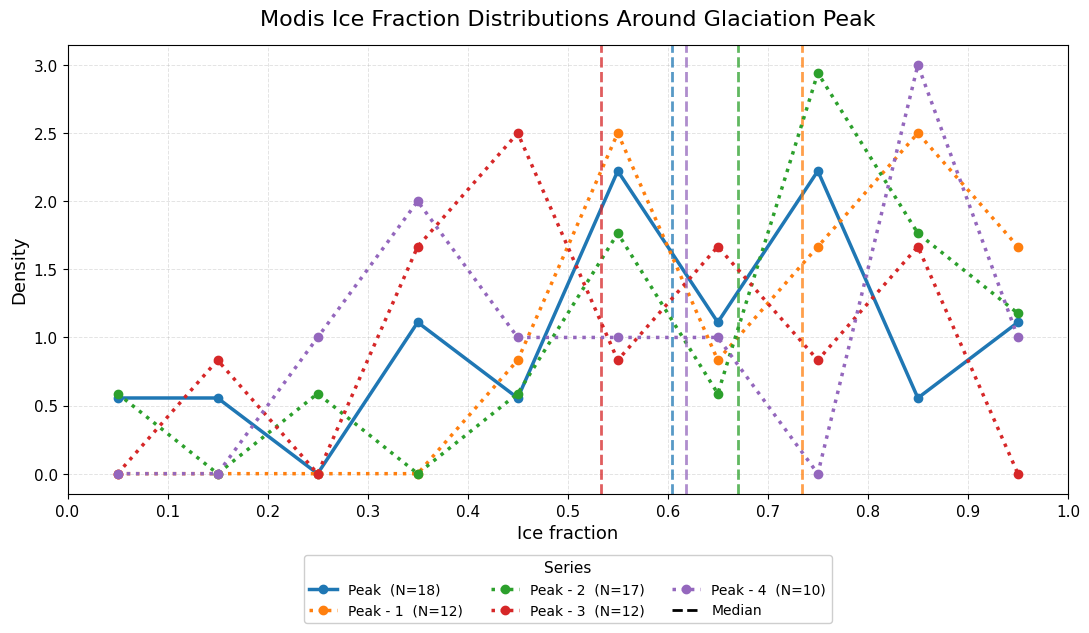

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# columns to compare
pre_peak_cols = [f"val_{i}_prepeak_if" for i in range(1, 5)]
all_cols = ["val_peak_if"] + pre_peak_cols

# nicer legend labels
label_map = {
    "val_peak_if": "Peak",
    "val_1_prepeak_if": "Peak - 1",
    "val_2_prepeak_if": "Peak - 2",
    "val_3_prepeak_if": "Peak - 3",
    "val_4_prepeak_if": "Peak - 4",
}

# fixed bins between 0 and 1
bins = np.linspace(0, 1.0, 11)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

plt.figure(figsize=(11, 6.5))

for col in all_cols:
    values = df_glac[col].dropna()
    values = values[(values >= 0) & (values <= 1)]

    counts, _ = np.histogram(values, bins=bins, density=True)
    median_val = np.mean(values)

    # make pre-peak lines dotted, keep peak solid
    linestyle = "-" if col == "val_peak_if" else ":"

    line, = plt.plot(
        bin_centers,
        counts,
        linestyle=linestyle,
        marker="o",
        markersize=6,
        linewidth=2.5,
        label=f"{label_map[col]}  (N={len(values)})"
    )

    plt.axvline(
        median_val,
        color=line.get_color(),
        linestyle="--",
        linewidth=2,
        alpha=0.75
    )

plt.xlabel("Ice fraction", fontsize=13)
plt.ylabel("Density", fontsize=13)
plt.title("Modis Ice Fraction Distributions Around Glaciation Peak", fontsize=16, pad=14)

plt.xlim(0, 1)
plt.xticks(np.arange(0, 1.01, 0.1), fontsize=11)
plt.yticks(fontsize=11)

plt.grid(True, linestyle="--", linewidth=0.7, alpha=0.35)

# add p-value annotation
# plt.text(
#     0.1, 0.95, "p = 0.13",
#     transform=plt.gca().transAxes,
#     ha="right", va="top",
#     fontsize=12,
#     bbox=dict(boxstyle="round,pad=0.3", facecolor="white", alpha=0.8, edgecolor="gray")
# )

# add a custom legend entry for the median lines
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(Line2D([0], [0], color="black", linestyle="--", linewidth=2, label="Median"))
labels.append("Median")

plt.legend(
    handles=handles,
    labels=labels,
    title="Series",
    title_fontsize=11,
    fontsize=10,
    frameon=True,
    fancybox=True,
    framealpha=0.95,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3
)

plt.tight_layout()
plt.show()

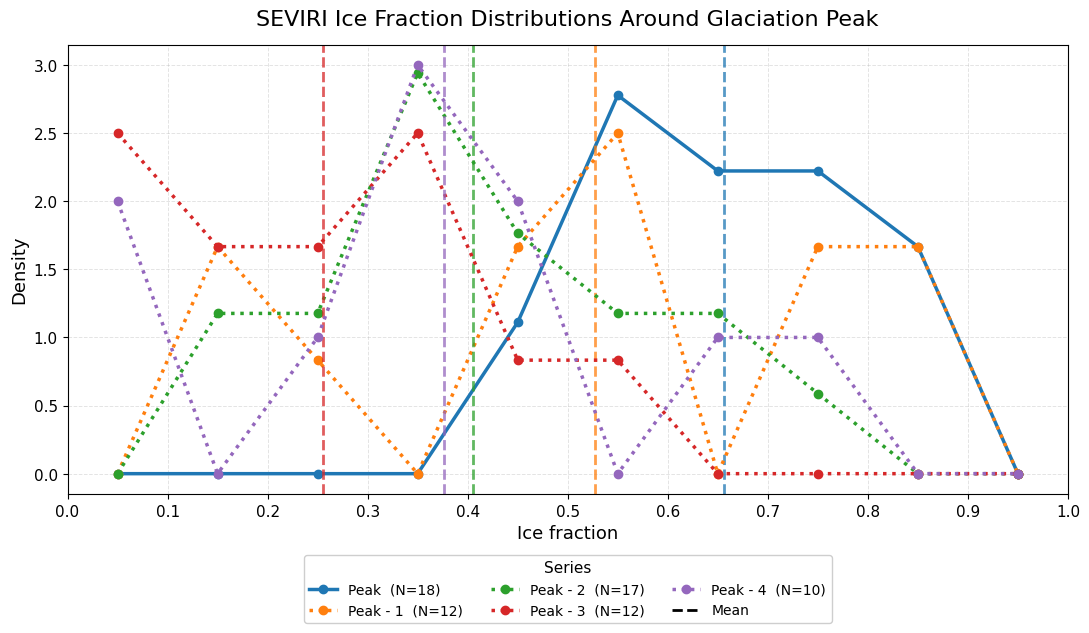

In [49]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# columns to compare
pre_peak_cols = [f"seviri_{i}_prepeak_if" for i in range(1, 5)]
all_cols = ["seviri_peak_if"] + pre_peak_cols

# nicer legend labels
label_map = {
    "seviri_peak_if": "Peak",
    "seviri_1_prepeak_if": "Peak - 1",
    "seviri_2_prepeak_if": "Peak - 2",
    "seviri_3_prepeak_if": "Peak - 3",
    "seviri_4_prepeak_if": "Peak - 4",
}

# fixed bins between 0 and 1
bins = np.linspace(0, 1.0, 11)
bin_centers = 0.5 * (bins[:-1] + bins[1:])

plt.figure(figsize=(11, 6.5))

for col in all_cols:
    values = df_glac[col].dropna()
    values = values[(values >= 0) & (values <= 1)]

    counts, _ = np.histogram(values, bins=bins, density=True)
    median_val = np.mean(values)

    # make pre-peak lines dotted, keep peak solid
    linestyle = "-" if col == "seviri_peak_if" else ":"

    line, = plt.plot(
        bin_centers,
        counts,
        linestyle=linestyle,
        marker="o",
        markersize=6,
        linewidth=2.5,
        label=f"{label_map[col]}  (N={len(values)})"
    )

    plt.axvline(
        median_val,
        color=line.get_color(),
        linestyle="--",
        linewidth=2,
        alpha=0.75
    )

plt.xlabel("Ice fraction", fontsize=13)
plt.ylabel("Density", fontsize=13)
plt.title("SEVIRI Ice Fraction Distributions Around Glaciation Peak", fontsize=16, pad=14)

plt.xlim(0, 1)
plt.xticks(np.arange(0, 1.01, 0.1), fontsize=11)
plt.yticks(fontsize=11)

plt.grid(True, linestyle="--", linewidth=0.7, alpha=0.35)

# add a custom legend entry for the median lines
handles, labels = plt.gca().get_legend_handles_labels()
handles.append(Line2D([0], [0], color="black", linestyle="--", linewidth=2, label="Mean"))
labels.append("Mean")

plt.legend(
    handles=handles,
    labels=labels,
    title="Series",
    title_fontsize=11,
    fontsize=10,
    frameon=True,
    fancybox=True,
    framealpha=0.95,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3
)

plt.tight_layout()
plt.show()

In [50]:
df_clouds["val_mean_if"] = df_clouds.apply(get_mean_val_ice_frac_hist, axis=1)
df_clouds["val_mean_if_dev"] = df_clouds.apply(get_if_dev_same_cloud, axis=1)

In [51]:

valid_glac= df_glac[~df_glac["val_mean_if_dev"].isna()]
valid_cloud= df_clouds[~df_clouds["val_mean_if_dev"].isna()]


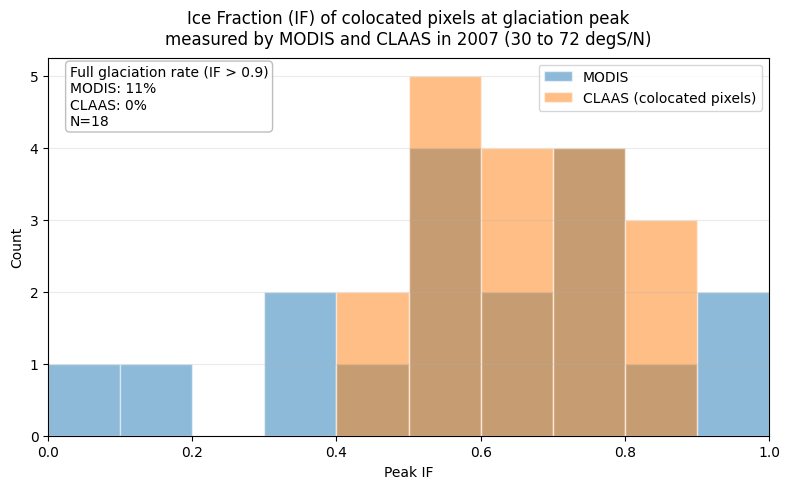

MODIS: 0.1111111111111111
Seviri: 0.0


In [65]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
val_peak_measurement_clouds = valid_glac[~valid_glac["val_peak_if"].isna()]
med = val_peak_measurement_clouds["val_peak_if"].median()

full_glac_frac_dd = (val_peak_measurement_clouds["val_peak_if"]>0.9).mean()
full_glac_frac_seviri = (val_peak_measurement_clouds["seviri_peak_if"]>0.9).mean()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(val_peak_measurement_clouds["val_peak_if"], bins=10, edgecolor="white", linewidth=1, alpha=0.5, range = (0,1), label = "MODIS")
ax.hist(val_peak_measurement_clouds["seviri_peak_if"], bins=10, edgecolor="white", linewidth=1, alpha=0.5, range = (0,1), label = "CLAAS (colocated pixels)")

summary = (
    "Full glaciation rate (IF > 0.9)\n"
    f"MODIS: {full_glac_frac_dd:.0%}\n"
    f"CLAAS: {full_glac_frac_seviri:.0%}\n"
    f"N={len(val_peak_measurement_clouds)}"
)

ax.text(
    0.03, 0.98, summary,
    transform=ax.transAxes,
    ha="left", va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="0.7")
)
# ax.axvline(med, linestyle="--", linewidth=2, label=f"Median = {med:.3g}", color="black")
ax.set_title("Ice Fraction (IF) of colocated pixels at glaciation peak\nmeasured by MODIS and CLAAS in 2007 (30 to 72 degS/N)", pad=10)
ax.set_xlabel("Peak IF")
ax.set_ylabel("Count")
ax.grid(True, axis="y", alpha=0.25)
legend = ax.legend(frameon=True)
# legend.set_title("Fully glaciating:\nSeviri: 15%\nMODIS: 56%")
# legend._legend_box.align = "left"
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(0,1)
plt.tight_layout()
plt.savefig("/wolke_scratch/dnikolo/MSGI/figures/MODIS_vs_SEVIRI_peak_if_whole_globe.png",dpi=300)
plt.show()
print("MODIS:",full_glac_frac_dd)
print("Seviri:",full_glac_frac_seviri)


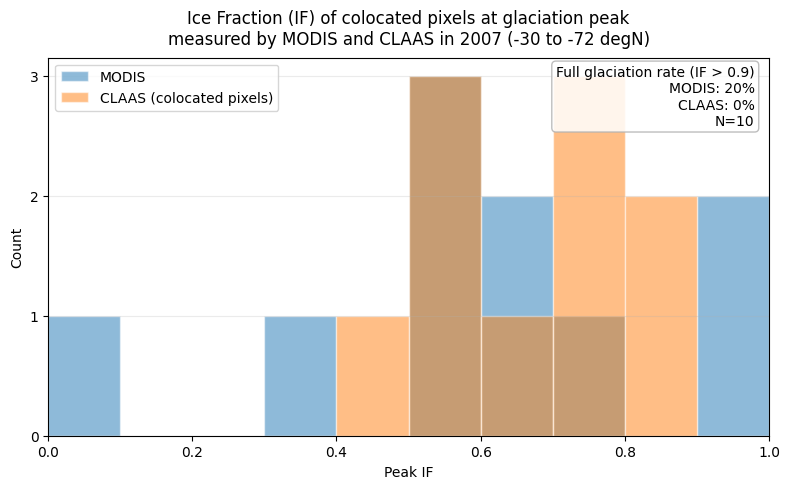

MODIS: 0.2
Seviri: 0.0


In [53]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
val_peak_measurement_clouds = valid_glac[~valid_glac["val_peak_if"].isna() & (valid_glac["Hemisphere"]=="South")]
med = val_peak_measurement_clouds["val_peak_if"].median()

full_glac_frac_dd = (val_peak_measurement_clouds["val_peak_if"]>0.9).mean()
full_glac_frac_seviri = (val_peak_measurement_clouds["seviri_peak_if"]>0.9).mean()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(val_peak_measurement_clouds["val_peak_if"], bins=10, edgecolor="white", linewidth=1, alpha=0.5, range = (0,1), label = "MODIS")
ax.hist(val_peak_measurement_clouds["seviri_peak_if"], bins=10, edgecolor="white", linewidth=1, alpha=0.5, range = (0,1), label = "CLAAS (colocated pixels)")

summary = (
    "Full glaciation rate (IF > 0.9)\n"
    f"MODIS: {full_glac_frac_dd:.0%}\n"
    f"CLAAS: {full_glac_frac_seviri:.0%}\n"
    f"N={len(val_peak_measurement_clouds)}"
)

ax.text(
    0.98, 0.98, summary,
    transform=ax.transAxes,
    ha="right", va="top",
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85, edgecolor="0.7")
)
# ax.axvline(med, linestyle="--", linewidth=2, label=f"Median = {med:.3g}", color="black")
ax.set_title("Ice Fraction (IF) of colocated pixels at glaciation peak\nmeasured by MODIS and CLAAS in 2007 (-30 to -72 degN)", pad=10)
ax.set_xlabel("Peak IF")
ax.set_ylabel("Count")
ax.grid(True, axis="y", alpha=0.25)
legend = ax.legend(frameon=True)
# legend.set_title("Fully glaciating:\nSeviri: 15%\nMODIS: 56%")
# legend._legend_box.align = "left"
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(0,1)
plt.tight_layout()
plt.savefig("/wolke_scratch/dnikolo/MSGI/figures/MODIS_vs_SEVIRI_peak_if_south.png",dpi=300)
plt.show()
print("MODIS:",full_glac_frac_dd)
print("Seviri:",full_glac_frac_seviri)


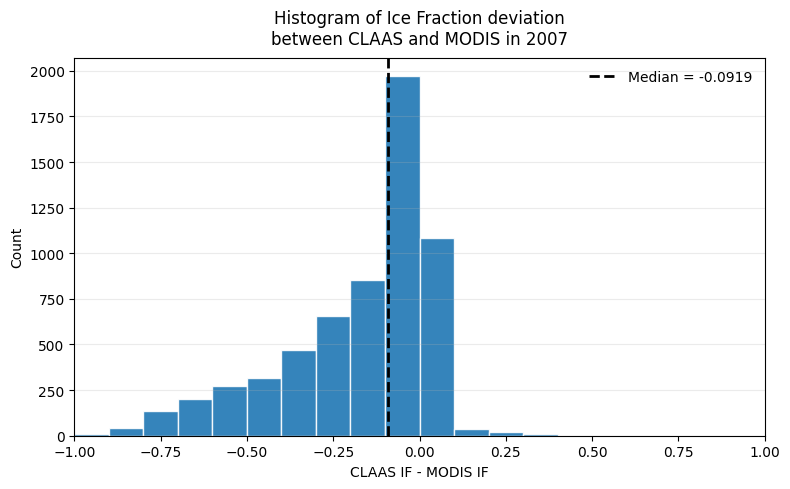

In [54]:
import matplotlib.pyplot as plt

s = valid_cloud["val_mean_if_dev"].dropna()
med = s.median()

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(s, bins=20, edgecolor="white", linewidth=1, alpha=0.9, range = (-1,1))
ax.axvline(med, linestyle="--", linewidth=2, label=f"Median = {med:.3g}", color="black")

ax.set_title("Histogram of Ice Fraction deviation\nbetween CLAAS and MODIS in 2007", pad=10)
ax.set_xlabel("CLAAS IF - MODIS IF")
ax.set_ylabel("Count")
ax.grid(True, axis="y", alpha=0.25)
ax.legend(frameon=False)
ax.set_xlim(-1,1)
plt.tight_layout()
plt.savefig("/wolke_scratch/dnikolo/MSGI/figures/MODIS_vs_SEVIRI_if_deviation.png",dpi=300)
plt.show()

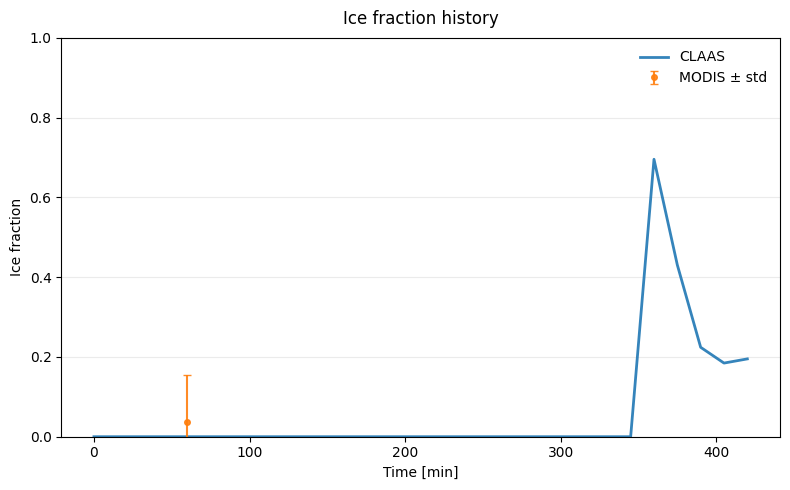

In [55]:
import numpy as np
import matplotlib.pyplot as plt

test_cloud = valid_glac.iloc[25]
claas_if_hist = test_cloud["ice_frac_hist"]
val_if_hist    = test_cloud["val_ice_frac_hist"]
val_if_std_hist = test_cloud["val_ice_frac_std_hist"].copy()

# clean std + validity mask
val_if_std_hist = np.array(val_if_std_hist, dtype=float)
val_if_std_hist[val_if_std_hist < 0] = np.nan

claas_if_hist = np.array(claas_if_hist, dtype=float)
val_if_hist    = np.array(val_if_hist, dtype=float)

valid_pixels = ~np.isnan(claas_if_hist) & ~np.isnan(val_if_hist) & (val_if_hist > -1)

x = np.arange(len(claas_if_hist))*15

fig, ax = plt.subplots(figsize=(8, 5))

# line (CLAAS)
ax.plot(x, claas_if_hist, linewidth=2, alpha=0.9, label="CLAAS")

# points + errorbars (DD), only for valid pixels
ax.errorbar(
    x[valid_pixels],
    val_if_hist[valid_pixels],
    yerr=val_if_std_hist[valid_pixels],
    fmt="o",
    linestyle="none",
    markersize=4,
    capsize=3,
    linewidth=1.5,
    alpha=0.9,
    label="MODIS ± std",
)

ax.set_title("Ice fraction history", pad=10)
ax.set_xlabel("Time [min]")
ax.set_ylabel("Ice fraction")
ax.set_ylim(0, 1)

ax.grid(True, axis="y", alpha=0.25)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

In [56]:
points_of_interest = test_cloud["val_cth_hist"] > 0
(np.abs(test_cloud["cth_hist"][points_of_interest] - test_cloud["val_cth_hist"][points_of_interest])).mean()

269.7388519446056

In [57]:
valid_glac[valid_glac.val_mean_if>=0]["val_ice_frac_dev_hist"]

Series([], Name: val_ice_frac_dev_hist, dtype: object)

## Statistics

### Validation

In [58]:
plt.hist(prepeak_if)
x = np.sort(prepeak_if)
plt.plot(x, expon.pdf(x, loc=0, scale=scale_2))

NameError: name 'prepeak_if' is not defined

In [ ]:
from scipy.stats import expon

peak_if = 1-df_glac["val_peak_if"].dropna().to_numpy()
prepeak_if = 1-df_glac["val_1_prepeak_if"][df_glac["val_1_prepeak_if"]>=0].dropna().to_numpy()
# Fit exponential with location fixed at 0
loc_1, scale_1 = expon.fit(peak_if, floc=0)
lambda_hat_1 = 1 / scale_1
loc_2, scale_2 = expon.fit(prepeak_if, floc=0)
lambda_hat_2 = 1 / scale_2
# expon.pdf(peak_if,loc=0,scale=scale_1).prod()
logL_1 = expon.logpdf(peak_if, loc=0, scale=scale_1).sum()
logL_2 = expon.logpdf(prepeak_if, loc=0, scale=scale_2).sum()
print(logL_1,logL_2, logL_1+logL_2)

37.73391443940757 24.31392639229569 62.04784083170326


In [ ]:
combined = np.concatenate([peak_if, prepeak_if])
loc_c, scale_c = expon.fit(combined, floc=0)

logL_c = expon.logpdf(combined, loc=0, scale=scale_c).sum()
logL_c


60.94148649798128

In [ ]:
T = 2*(logL_1+logL_2-logL_c)
p_value = chi2.sf(T, df=1)
p_value

0.136878153265528

In [ ]:
loc_2

0.0

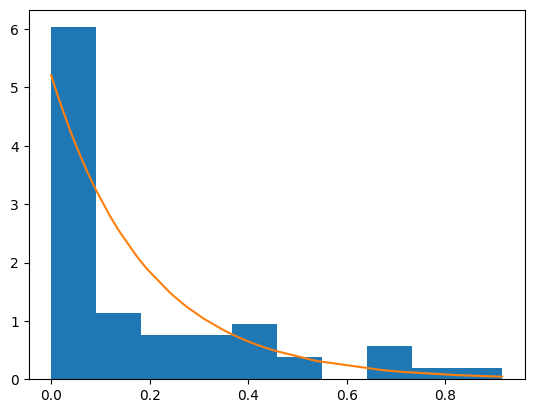

In [ ]:
plt.hist(peak_if,density=True)
x = np.sort(peak_if)
plt.plot(x, expon.pdf(x, loc=0, scale=scale_1))

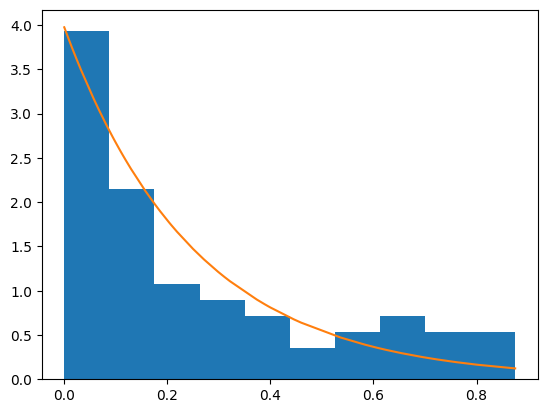

In [ ]:
plt.hist(prepeak_if,density=True)
x = np.sort(prepeak_if)
plt.plot(x, expon.pdf(x, loc=0, scale=scale_2))

In [ ]:
from scipy.stats import chi2

x = 10.5   # chi-square statistic
df = 1     # degrees of freedom

p_value = chi2.sf(lambda_hat_1/lambda_hat_2, df)   # survival function = 1 - cdf
print(p_value)

0.25223990282102915


In [ ]:
print(lambda_hat_1,lambda_hat_2,lambda_hat_1/lambda_hat_2)

5.210025403754389 3.9745244267502815 1.3108550468802374
